In [46]:
import numpy as np
import pandas as pd
## Import scan metrics
#df = pd.read_csv("./tables/RF_opti_Genveva2022.csv")
df = pd.read_pickle("./tables/RF_opti_Geneva2022_all.pkl")

In [93]:
ax.text(row["OA_train"]-0.05, row["OA"]-0.01, ...)

Text(93.01666666666667, 85.79645161290323, 'Ellipsis')

NameError: name 'df' is not defined

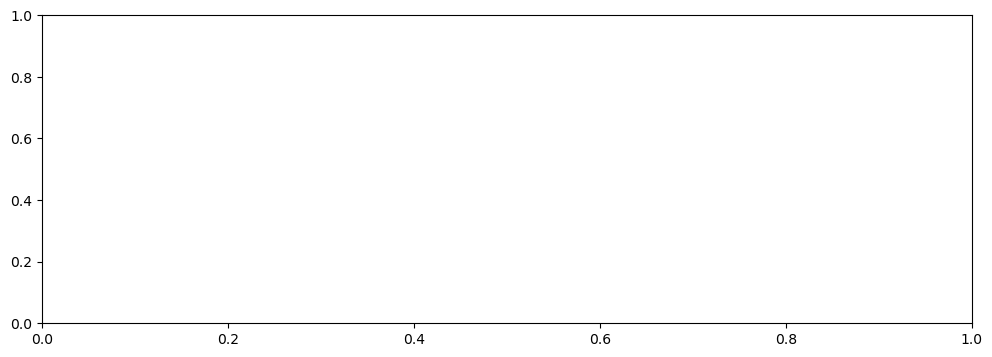

In [1]:
import matplotlib.pyplot as plt
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(12, 4))

palette = plt.cm.tab20b
palette = ['darkturquoise','dodgerblue','mediumslateblue']
cats = sorted(df["numberOfTrees"].unique())
color_map = {cat: palette[i %len(palette)] for i, cat in enumerate(cats)}

texts = []

for cat, group in df.groupby("numberOfTrees"):
    ax.scatter(
        group["OA_train"],
        group["OA"],
        s=30,
        marker='x',
        color=color_map[cat],
        label=f"{cat} trees"
    )

    for _, row in group.iterrows():
        label = f"({row['numberOfTrees']},{row['variablesPerSplit']},{row['minLeafPopulation']})"

        txt = ax.text(
            row["OA_train"],
            row["OA"],
            label,
            fontsize=8,
            color=color_map[cat]
        )
        texts.append(txt)

adjust_text(
    texts,
    ax=ax,
    expand_text=(1.2, 1.3),
    expand_points=(1.2, 1.3),
    expand_axes=True,
    prevent_crossings=True,
    force_text=(0.5, 0.8),
    force_points=(0.3, 0.5)#,
    #arrowprops=dict(arrowstyle='-', lw=0.5, alpha=0.6)
)

ax.legend(title="numberOfTrees")

ax.plot([0, 1], [0, 1], "--", alpha=0.5)

ax.set_xlim(0.99 * df["OA_train"].min(), 1.01 * df["OA_train"].max())
ax.set_ylim(0.99 * df["OA"].min(), 1.01 * df["OA"].max())

ax.set_xlabel("OA train [%]")
ax.set_ylabel("OA validation [%]")
ax.grid(alpha=0.3)

plt.savefig("./images/RF_opti_geneva_OAscatter.png", dpi=600)
plt.show()

In [116]:
records = df[df['numberOfTrees'] == 500]
#records['OA', 'variablesPerSplit','minLeafPopulation']
df.columns
df_sorted = df.sort_values(by='numberOfTrees')
df_sorted.to_excel('./tables/RF_opti_geneva_2022_results.xlsx', index=False)


In [121]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "Compact MR",
    "Open MR",
    "Open LR",
    "Large LR",
    "Dense Trees",
    "Low plants",
    "Bare rock/Paved",
    "Water"
]

# labels for x-axis


scan_labels = (
    "("
    + df["numberOfTrees"].astype(str)
    + ","
    + df["variablesPerSplit"].astype(str)
    + ","
    + df["minLeafPopulation"].astype(str)
    + ")"
).tolist()

labels=[]
for _, row in df.iterrows():

    labels.append(
        f"({row['numberOfTrees']},"
        f"{row['variablesPerSplit']},"
        f"{row['minLeafPopulation']})"
    )


x = np.arange(len(df))
width = 0.4

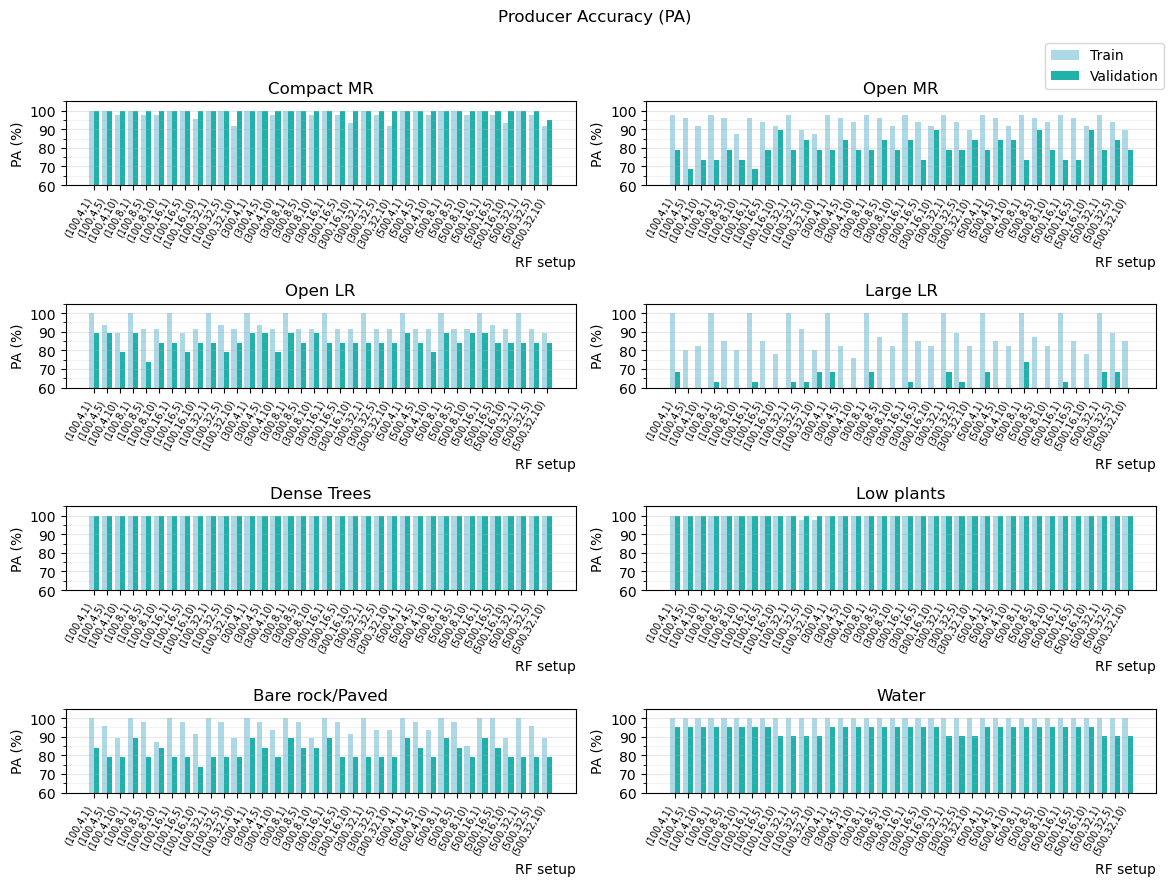

In [158]:
import matplotlib.ticker as ticker


fig_pa, axes = plt.subplots(
    4, 2,
    figsize=(12, 9),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for iclass, cname in enumerate(class_names):

    pa_train = df["PA_train"].apply(lambda v: v[iclass]).to_numpy()
    pa_val   = df["PA"].apply(lambda v: v[iclass]).to_numpy()


    ax = axes[iclass]

    ax.bar(x - width/2, pa_train, width, label="Train", color='lightblue')
    ax.bar(x + width/2, pa_val, width, label="Validation", color='lightseagreen')

    ax.set_title(cname)
    ax.set_xlabel("RF setup", loc='right')
    ax.set_ylabel("PA (%)")
    ax.set_ylim(60,105)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
    ax.grid(which="major", axis="y", alpha=0.3)
    ax.grid(which="minor", axis="y", alpha=0.15)

#axes[0].legend()

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7, rotation=60, ha='right')

fig_pa.suptitle("Producer Accuracy (PA)")

handles, labels_leg = axes[0].get_legend_handles_labels()

fig_pa.legend(
    handles,
    labels_leg,
    loc='upper right',
    bbox_to_anchor=(0.98, 0.95)
)

fig_pa.tight_layout(rect=[0, 0, 0.98, 0.95])
fig_pa.savefig("./images/RF_opti_PA.png", dpi=600, transparent=True, bbox_inches='tight')



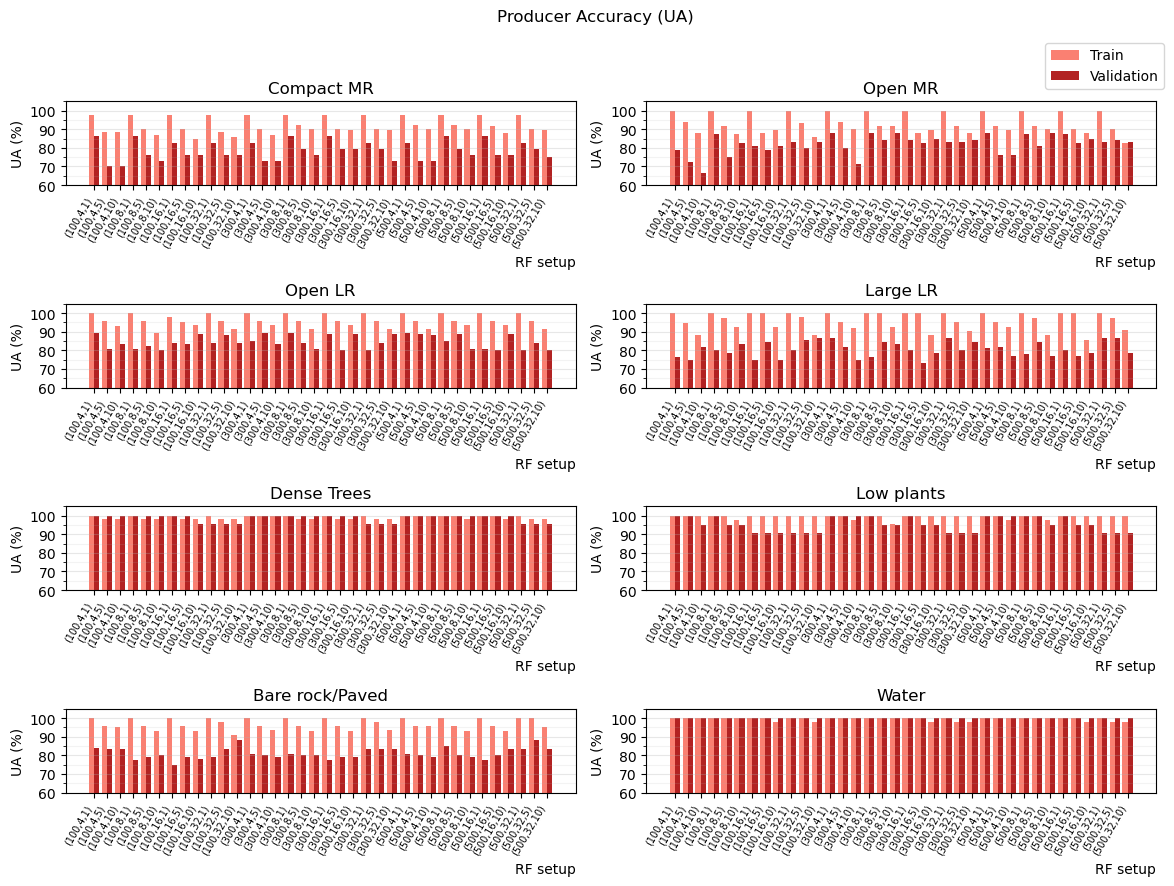

In [159]:
import matplotlib.ticker as ticker


fig_pa, axes = plt.subplots(
    4, 2,
    figsize=(12, 9),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for iclass, cname in enumerate(class_names):

    pa_train = df["UA_train"].apply(lambda v: v[iclass]).to_numpy()
    pa_val   = df["UA"].apply(lambda v: v[iclass]).to_numpy()


    ax = axes[iclass]

    ax.bar(x - width/2, pa_train, width, label="Train", color='salmon')
    ax.bar(x + width/2, pa_val, width, label="Validation", color='firebrick')

    ax.set_title(cname)
    ax.set_xlabel("RF setup", loc='right')
    ax.set_ylabel("UA (%)")
    ax.set_ylim(60,105)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
    ax.grid(which="major", axis="y", alpha=0.3)
    ax.grid(which="minor", axis="y", alpha=0.15)

#axes[0].legend()

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7, rotation=60, ha='right')

fig_pa.suptitle("Producer Accuracy (UA)")

handles, labels_leg = axes[0].get_legend_handles_labels()

fig_pa.legend(
    handles,
    labels_leg,
    loc='upper right',
    bbox_to_anchor=(0.98, 0.95)
)

fig_pa.tight_layout(rect=[0, 0, 0.98, 0.95])
fig_pa.savefig("./images/RF_opti_UA.png", dpi=600, transparent=True, bbox_inches='tight')

